# Neural sentiment classifiers
## Dense network tuning
Select a Dense network using macro F1 on a stratified validation split. The model averages token embeddings before the hidden layer, so its predictions are insensitive to word order. The 200 test comments are reserved for final evaluation.

In [1]:
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
from src.models import build_dense
from src.preprocessing import (
    MAX_LEN, SEED, build_vectorizer, load_splits, train_val_split,
    vectorize, vocabulary_size,
)
from src.train import BASE_GRID, grid_search, train_model
from src.visualize import plot_learning_curves

In [2]:
texts, labels, _, _ = load_splits()
texts_tr, texts_val, y_tr, y_val = train_val_split(texts, labels, seed=SEED)
vectorizer = build_vectorizer(texts_tr, max_len=MAX_LEN)
vocab_size = vocabulary_size(vectorizer)
X_tr = vectorize(vectorizer, texts_tr)
X_val = vectorize(vectorizer, texts_val)
assert X_tr.shape == (680, MAX_LEN) and X_val.shape == (120, MAX_LEN)
assert np.bincount(y_tr).tolist() == [340, 340]
assert np.bincount(y_val).tolist() == [60, 60]
print(f"Training: {len(y_tr)} | Validation: {len(y_val)} | Vocabulary: {vocab_size}")

Training: 680 | Validation: 120 | Vocabulary: 2138


### Grid and selection rule
Use the same split and seed for all 48 trials. Each trial restores the epoch with the lowest validation loss. Rank the restored models by validation macro F1 and break ties using validation loss. The table shows the five highest-ranked configurations.

In [3]:
dense_grid = grid_search(
    build_dense, BASE_GRID, X_tr, y_tr, X_val, y_val,
    vocab_size=vocab_size, epochs=30, seed=SEED,
)
assert len(dense_grid) == 48 and not dense_grid.duplicated(list(BASE_GRID)).any()
dense_grid.loc[:, [*BASE_GRID, "val_f1_macro", "val_accuracy", "best_val_loss", "best_epoch"]].head(5)

,embed_dim,units,dropout,lr,batch_size,val_f1_macro,val_accuracy,best_val_loss,best_epoch
0,32,32,0.5,0.003,32,0.758182,0.758333,0.554038,4
1,32,32,0.2,0.003,16,0.757913,0.758333,0.543800,2
2,32,32,0.2,0.003,32,0.749931,0.750000,0.540455,3
3,32,32,0.5,0.001,32,0.749722,0.750000,0.548143,8
4,32,32,0.5,0.001,16,0.749722,0.750000,0.550326,5


### Learning curves for the selected configuration
Repeat the winning trial with the same seed and plot training and validation loss and accuracy. The dotted line marks the epoch restored by early stopping.

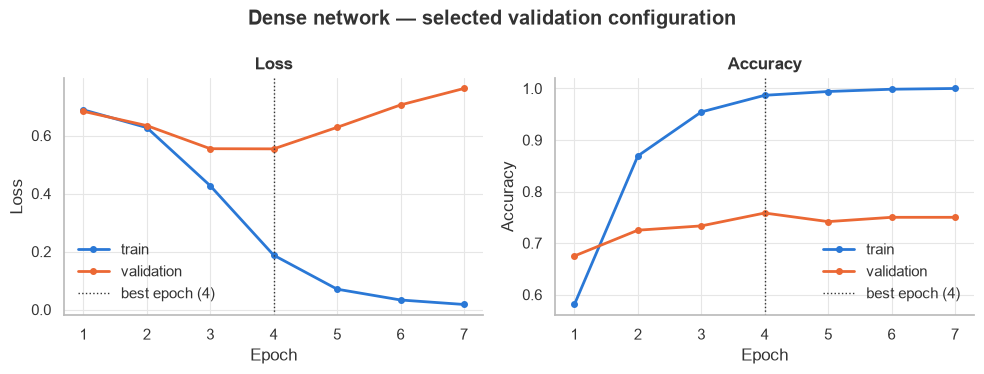

In [4]:
best = dense_grid.iloc[0]
dense_params = dict(
    vocab_size=vocab_size, max_len=MAX_LEN, embed_dim=int(best.embed_dim),
    units=int(best.units), dropout=float(best.dropout), lr=float(best.lr),
)
dense_history, _ = train_model(
    build_dense, dense_params, X_tr, y_tr, X_val, y_val,
    batch_size=int(best.batch_size), epochs=30, seed=SEED,
)
dense_fig = plot_learning_curves(
    dense_history, title="Dense network — selected validation configuration",
    name="03_dense_learning_curves",
)

In [5]:
hist = dense_history.history
epoch = int(np.argmin(hist["val_loss"]))
spread = best.val_f1_macro - dense_grid.iloc[4].val_f1_macro
print(f"Best validation macro F1: {best.val_f1_macro:.3f}. "
      f"Difference from fifth place: {spread:.3f}.")
print(f"At the refit's minimum validation loss (epoch {epoch + 1}), "
      f"training accuracy was {hist['accuracy'][epoch]:.1%} "
      f"and validation accuracy was {hist['val_accuracy'][epoch]:.1%}.")

Best validation macro F1: 0.758. Difference from fifth place: 0.008.
At the refit's minimum validation loss (epoch 4), training accuracy was 98.7% and validation accuracy was 75.8%.


## Vanilla RNN tuning
The SimpleRNN reads token embeddings in sequence and classifies each comment from its final hidden state. Use the same 48 configurations, training and validation split, seed and ranking rule as the Dense experiment.

In [6]:
from src.models import build_rnn

rnn_grid = grid_search(
    build_rnn, BASE_GRID, X_tr, y_tr, X_val, y_val,
    vocab_size=vocab_size, epochs=30, seed=SEED,
)
assert len(rnn_grid) == 48 and not rnn_grid.duplicated(list(BASE_GRID)).any()
rnn_grid.loc[:, [*BASE_GRID, "val_f1_macro", "val_accuracy", "best_val_loss", "best_epoch"]].head(5)

,embed_dim,units,dropout,lr,batch_size,val_f1_macro,val_accuracy,best_val_loss,best_epoch
0,32,64,0.5,0.001,16,0.628274,0.633333,0.684271,1
1,64,64,0.5,0.003,16,0.624765,0.625000,0.751739,3
2,64,32,0.2,0.003,32,0.615357,0.625000,0.670363,1
3,32,32,0.2,0.001,16,0.614955,0.616667,0.666775,2
4,32,32,0.5,0.001,16,0.607652,0.608333,0.666948,2


### Learning curves for the selected configuration
Repeat the winning trial with the same seed and plot training and validation loss and accuracy. The dotted line marks the epoch restored by early stopping.

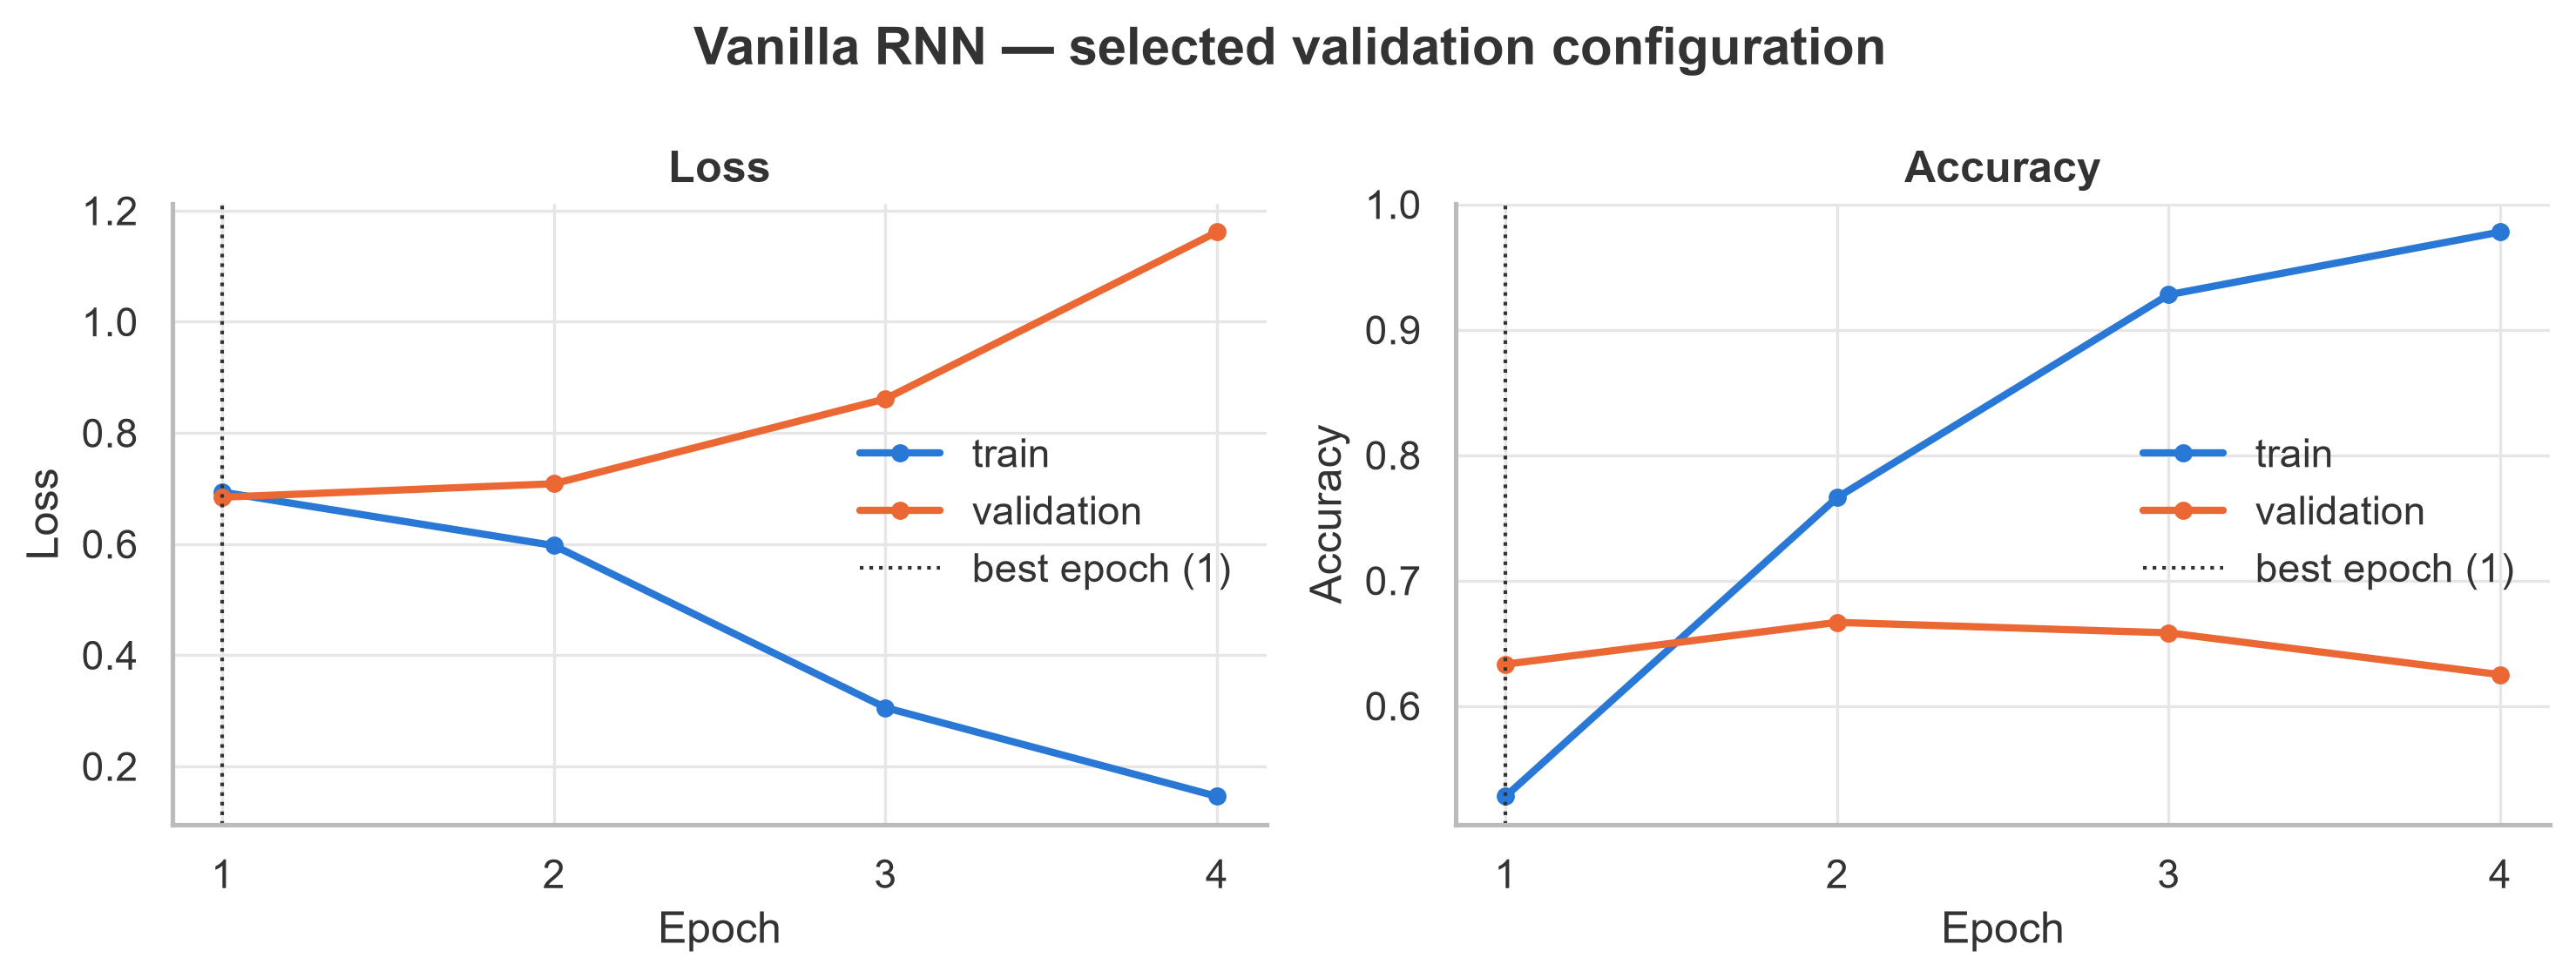

In [7]:
rnn_best = rnn_grid.iloc[0]
rnn_params = dict(
    vocab_size=vocab_size, max_len=MAX_LEN, embed_dim=int(rnn_best.embed_dim),
    units=int(rnn_best.units), dropout=float(rnn_best.dropout), lr=float(rnn_best.lr),
)
rnn_history, _ = train_model(
    build_rnn, rnn_params, X_tr, y_tr, X_val, y_val,
    batch_size=int(rnn_best.batch_size), epochs=30, seed=SEED,
)
rnn_fig = plot_learning_curves(
    rnn_history, title="Vanilla RNN — selected validation configuration",
    name="03_rnn_learning_curves",
)

In [8]:
hist = rnn_history.history
epoch = int(np.argmin(hist["val_loss"]))
spread = rnn_best.val_f1_macro - rnn_grid.iloc[4].val_f1_macro
print(f"Best validation macro F1: {rnn_best.val_f1_macro:.3f}. "
      f"Difference from fifth place: {spread:.3f}.")
print(f"At the refit's minimum validation loss (epoch {epoch + 1}), "
      f"training accuracy was {hist['accuracy'][epoch]:.1%} "
      f"and validation accuracy was {hist['val_accuracy'][epoch]:.1%}.")

Best validation macro F1: 0.628. Difference from fifth place: 0.021.
At the refit's minimum validation loss (epoch 1), training accuracy was 52.8% and validation accuracy was 63.3%.


The selected SimpleRNN scored 0.6283 macro F1 on validation, compared with 0.7582 for Dense on the same split. Its validation loss was lowest after the first epoch, so the three additional epochs did not improve the checkpoint. For this seed, processing tokens in order did not improve validation performance.

## LSTM tuning
The LSTM uses gates to control what it keeps or forgets as it reads the token sequence. Compare its 48 configurations on the same training and validation split, with seed 42 and the same ranking rule used for Dense and SimpleRNN.

In [9]:
from src.models import build_lstm

lstm_grid = grid_search(
    build_lstm, BASE_GRID, X_tr, y_tr, X_val, y_val,
    vocab_size=vocab_size, epochs=30, seed=SEED,
)
assert len(lstm_grid) == 48 and not lstm_grid.duplicated(list(BASE_GRID)).any()
lstm_grid.loc[:, [*BASE_GRID, "val_f1_macro", "val_accuracy", "best_val_loss", "best_epoch"]].head(5)

,embed_dim,units,dropout,lr,batch_size,val_f1_macro,val_accuracy,best_val_loss,best_epoch
0,64,32,0.5,0.003,32,0.733037,0.733333,0.580022,2
1,32,64,0.2,0.003,32,0.724828,0.725000,0.558476,2
2,32,16,0.5,0.001,32,0.724522,0.725000,0.556235,5
3,32,16,0.5,0.003,32,0.721734,0.725000,0.591292,2
4,32,16,0.2,0.001,32,0.715957,0.716667,0.557308,5


### Learning curves for the selected configuration
Repeat the winning trial with the same seed and plot training and validation loss and accuracy. The dotted line marks the epoch restored by early stopping.

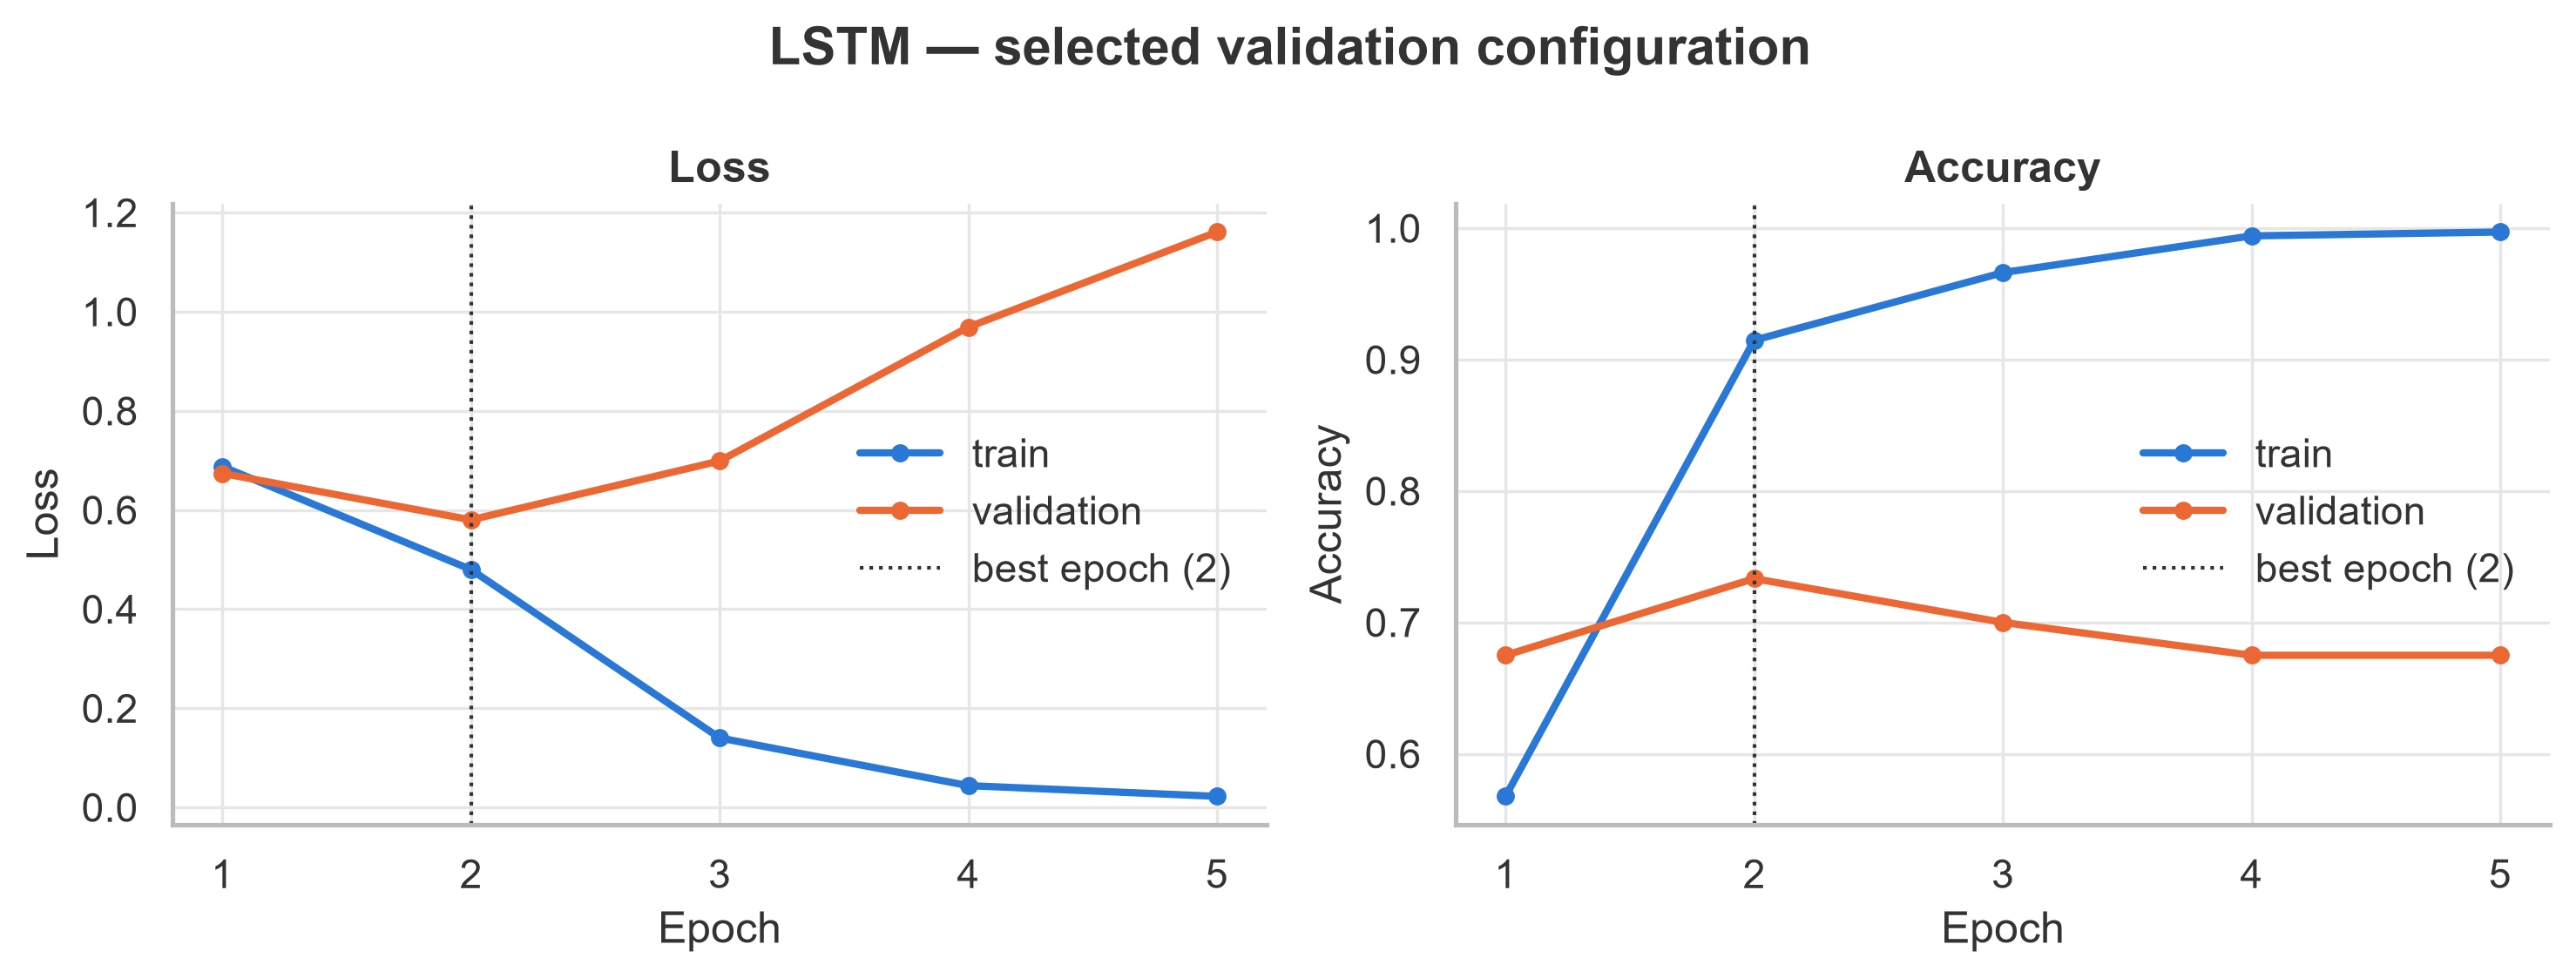

In [10]:
lstm_best = lstm_grid.iloc[0]
lstm_params = dict(
    vocab_size=vocab_size, max_len=MAX_LEN, embed_dim=int(lstm_best.embed_dim),
    units=int(lstm_best.units), dropout=float(lstm_best.dropout), lr=float(lstm_best.lr),
)
lstm_history, _ = train_model(
    build_lstm, lstm_params, X_tr, y_tr, X_val, y_val,
    batch_size=int(lstm_best.batch_size), epochs=30, seed=SEED,
)
lstm_fig = plot_learning_curves(
    lstm_history, title="LSTM — selected validation configuration",
    name="03_lstm_learning_curves",
)

In [11]:
hist = lstm_history.history
epoch = int(np.argmin(hist["val_loss"]))
spread = lstm_best.val_f1_macro - lstm_grid.iloc[4].val_f1_macro
print(f"Best validation macro F1: {lstm_best.val_f1_macro:.3f}. "
      f"Difference from fifth place: {spread:.3f}.")
print(f"At the refit's minimum validation loss (epoch {epoch + 1}), "
      f"training accuracy was {hist['accuracy'][epoch]:.1%} "
      f"and validation accuracy was {hist['val_accuracy'][epoch]:.1%}.")

Best validation macro F1: 0.733. Difference from fifth place: 0.017.
At the refit's minimum validation loss (epoch 2), training accuracy was 91.5% and validation accuracy was 73.3%.


The best LSTM used 64-dimensional embeddings, 32 recurrent units, dropout 0.5, learning rate 0.003 and batch size 32. On the same 120 validation comments and seed 42, its macro F1 was 0.7330, above SimpleRNN (0.6283) and below Dense (0.7582). The winning refit reached its minimum validation loss (0.5800) at epoch 2 and stopped after epoch 5. At epoch 2 training accuracy was 91.5% while validation accuracy was 73.3%, an 18.2 percentage point gap.

## Final evaluation over five seeds
For each grid winner, use the original 680/120 split to select the epoch count separately for seeds 42 through 46. Choose the seed to export by validation macro F1, breaking ties by lower validation loss and then lower seed. Rebuild each seed from scratch on all 800 training comments for its selected epoch count. Use the full-training vocabulary for the final models. Evaluate all five runs on train and the same 200 test comments at threshold 0.5. Each CSV reports the final fit time and parameter count. The standard deviation measures variation across seeds with the dataset held fixed.

To run this section independently, run the setup cell first. It reads the saved tuning grids.

In [12]:
from src.final_evaluation import run_final_evaluation

final_trials = run_final_evaluation()
final_trials

,model,seed,epochs,val_f1_macro,val_loss,saved
0,dense,42,4,0.758182,0.554038,True
1,dense,43,4,0.700000,0.563874,False
2,dense,44,3,0.728507,0.551384,False
3,dense,45,3,0.699917,0.559636,False
4,dense,46,3,0.647539,0.586779,False
5,rnn,42,1,0.628274,0.684271,False
6,rnn,43,1,0.502222,0.690351,False
7,rnn,44,1,0.531250,0.687201,False
8,rnn,45,1,0.506885,0.687825,False
9,rnn,46,2,0.665179,0.643770,True


In [13]:
from src.evaluate import load_all_metrics, summarize

all_metrics = load_all_metrics()
final_scores = summarize(all_metrics[all_metrics.model.isin(final_trials.model)])
final_scores

,model,split,n_runs,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,f1_macro_mean,f1_macro_std,kappa_mean,kappa_std,train_time_s_mean,train_time_s_std,n_params_mean,n_params_std
0,dense,test,5,0.74400,0.038308,0.726986,0.064782,0.8020,0.059330,0.758861,0.018379,0.740799,0.043189,0.4880,0.076616,0.855176,0.057807,76801.0,0.0
1,dense,train,5,0.99025,0.006398,0.990120,0.011546,0.9905,0.006225,0.990272,0.006341,0.990249,0.006399,0.9805,0.012796,0.855176,0.057807,76801.0,0.0
2,lstm,test,5,0.70400,0.019812,0.711966,0.065985,0.7140,0.109225,0.704392,0.032360,0.700592,0.021269,0.4080,0.039623,1.505595,0.121852,163873.0,0.0
3,lstm,train,5,0.94550,0.040664,0.975002,0.015625,0.9150,0.086114,0.942073,0.046611,0.945198,0.041232,0.8910,0.081329,1.505595,0.121852,163873.0,0.0
4,rnn,test,5,0.56300,0.035812,0.562103,0.029877,0.5300,0.207846,0.530596,0.125761,0.550729,0.046952,0.1260,0.071624,1.301004,0.108169,81985.0,0.0
5,rnn,train,5,0.81625,0.101014,0.855962,0.046753,0.7570,0.208097,0.792175,0.138668,0.812023,0.107392,0.6325,0.202029,1.301004,0.108169,81985.0,0.0


## Test confusion matrices and recurrent-model errors
The learning curves above show training and validation during tuning (seed 42). Here we score the three exported full-training models on the same 200 test comments. Each matrix refers to one checkpoint selected by validation. Run the setup cell and this section to reproduce the figures without retraining.

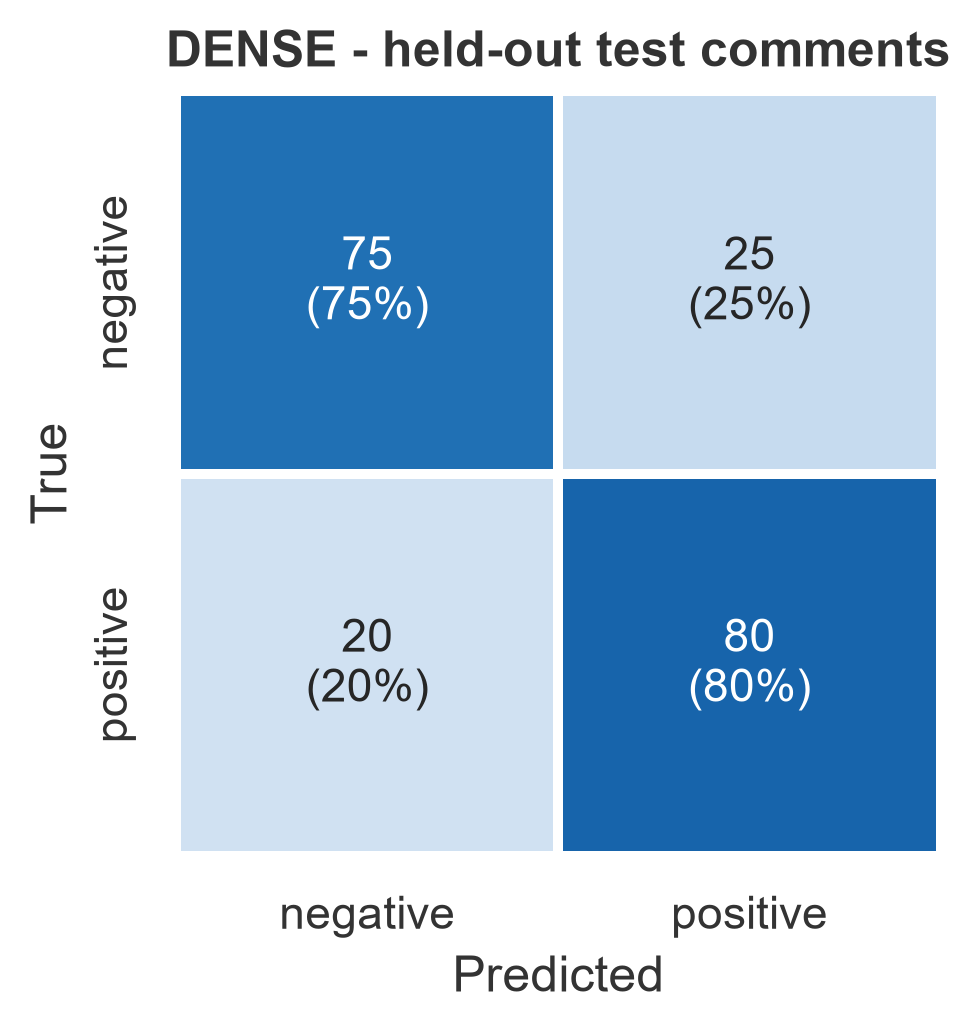

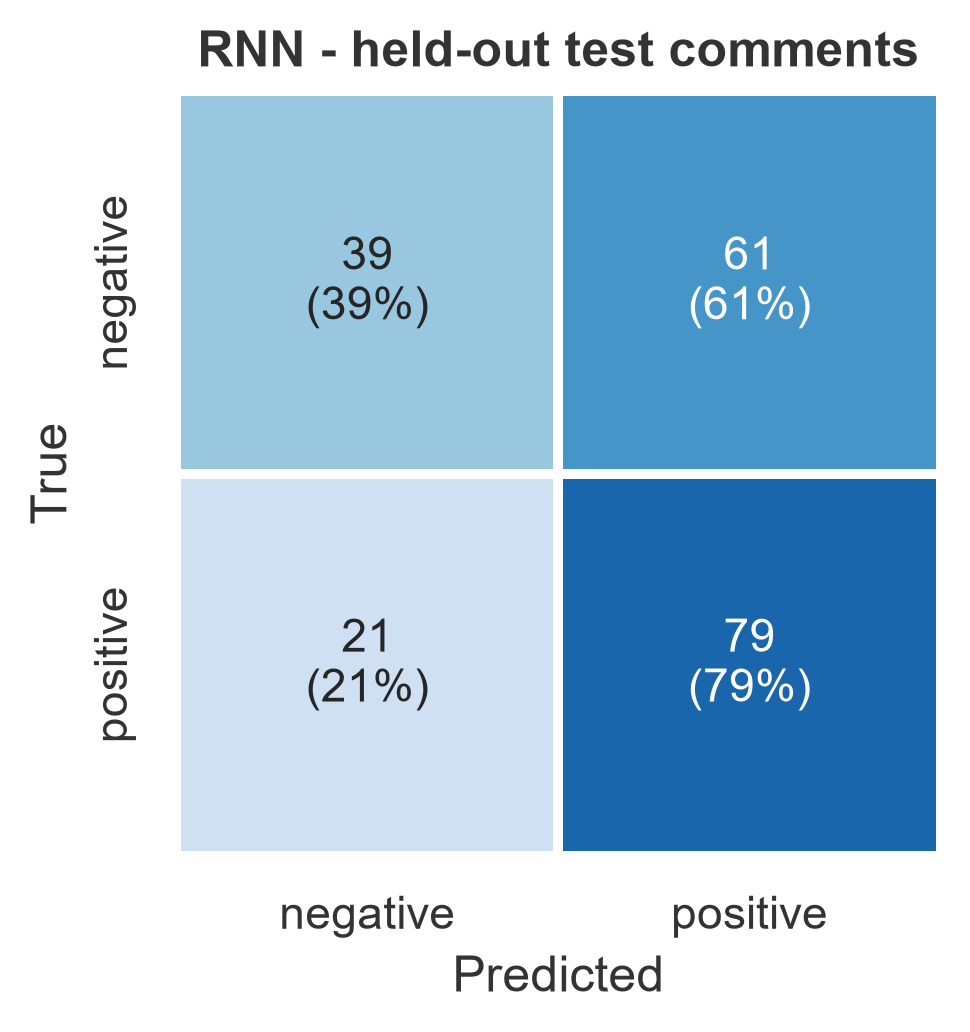

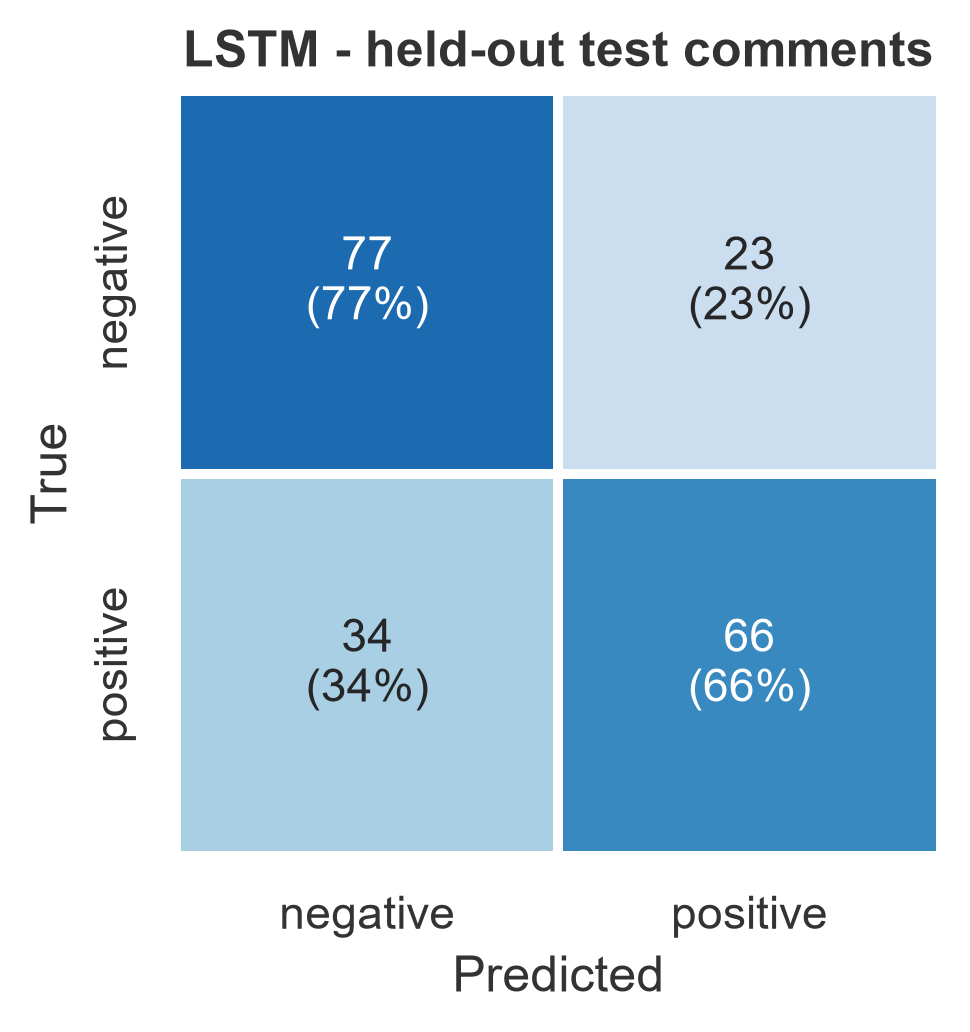

In [14]:
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from IPython.display import Image, display
from src.evaluate import confusion, predict_labels
from src.preprocessing import VOCAB_PATH
from src.visualize import plot_confusion

test_cases = pd.read_csv(root / "data/processed/test.csv", keep_default_na=False)
assert test_cases.comment_id.is_unique
test_vectorizer = tf.keras.layers.TextVectorization(
    vocabulary=VOCAB_PATH.read_text(encoding="utf8").splitlines(),
    standardize=None, split="whitespace", output_sequence_length=MAX_LEN,
)
test_tokens = test_vectorizer(tf.constant(test_cases.clean_text.tolist()))
for name in ("dense", "rnn", "lstm"):
    model = tf.keras.models.load_model(root / "outputs/saved_models" / f"{name}.keras", compile=False)
    labels = predict_labels(model.predict(test_tokens, verbose=0))
    test_cases[name] = labels
    matrix = confusion(test_cases.label, labels)
    assert matrix.sum(axis=1).tolist() == [100, 100]
    filename = f"03_{name}_test_confusion"
    fig = plot_confusion(cm=matrix, title=f"{name.upper()} - held-out test comments", name=filename)
    plt.close(fig)
    display(Image(filename=str(root / "outputs/figures" / f"{filename}.png")))

In [15]:
rnn_correct = test_cases.rnn.eq(test_cases.label)
lstm_correct = test_cases.lstm.eq(test_cases.label)
print(f"Both correct: {(rnn_correct & lstm_correct).sum()} | Both wrong: {(~rnn_correct & ~lstm_correct).sum()}")
print(f"Only LSTM correct: {(~rnn_correct & lstm_correct).sum()} | Only RNN correct: {(rnn_correct & ~lstm_correct).sum()}")

case_ids = ["ef9cy2a", "eesb4ga", "ee5un57", "ee4ayz5"]
examples = test_cases.set_index("comment_id").loc[case_ids, ["clean_text", "sentiment", "rnn", "lstm"]].copy()
for name in ("rnn", "lstm"):
    examples[name] = examples[name].map({0: "negative", 1: "positive"})
print("Token ID for frowning_face:", int(test_vectorizer(tf.constant(["frowning_face"]))[0, 0]))
examples

Both correct: 94 | Both wrong: 33
Only LSTM correct: 49 | Only RNN correct: 24
Token ID for frowning_face: 1


,clean_text,sentiment,rnn,lstm
comment_id,,,,
ef9cy2a,like bunch vaguely veiled racists sexists maga...,negative,positive,positive
eesb4ga,not find bad always favoured 1500m wife abu dhabi,positive,positive,negative
ee5un57,still gotta watch last one frowning_face,negative,positive,negative
ee4ayz5,nametoken problem forever hopefully fixes gets...,positive,positive,negative


### What the errors show
At the minimum validation loss during tuning, Dense reached 98.7% training accuracy versus 75.8% validation accuracy (epoch 4), and LSTM reached 91.5% versus 73.3% (epoch 2). SimpleRNN reached its minimum earlier, at epoch 1 (52.8% versus 63.3%). Its later epochs did not improve validation loss.

On test, the exported RNN called 61 of 100 negative comments positive. LSTM reduced that count to 23, but missed 34 of 100 positives compared with 21 for the RNN. Dense missed 20 positives and 25 negatives. The paired examples below illustrate possible readings of individual comments.

- **Possible irony, ef9cy2a.** Both recurrent models predicted positive for a comment labeled disgust. The author questions whether racism and sexism count as “good.” The cleaned input retains the word good and drops its quotation marks.
- **Negation, eesb4ga.** “I didn't find it too bad” expresses approval. The cleaned tokens retain both not and bad. SimpleRNN predicted positive and LSTM predicted negative.
- **Emoji, ee5un57.** A frowning face accompanies a comment labeled disappointment and sadness. The cleaner produces frowning_face, which maps to unknown ID 1. LSTM classified this comment correctly and SimpleRNN missed it. The LSTM prediction cannot be credited to a learned embedding specific to this emoji.
- **Masked name, ee4ayz5.** The dataset labels this comment optimism. After nametoken, the input mixes hopefully with problem and relationship killer. SimpleRNN matched the positive label and LSTM predicted negative. The mask hides the person's identity, while the surrounding text still contains conflicting sentiment cues.